## 모델 노트북입니다

In [1]:
# 모듈 임포트 셀
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, balanced_accuracy_score, confusion_matrix
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

In [2]:
plt.rcParams["font.family"] = "AppleGothic" # 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("../outputs", exist_ok=True)
SEED = 42
MIN_CAT = 50   # 이 수 미만인 범주는 기타로 묶음

In [3]:
# 데이터 불러오기
df = pd.read_csv("../data/clean.csv", encoding="utf-8-sig")
print(df.shape)

(13389, 60)


In [4]:
# 피처 선정. 라벨 기간(22년 이후)과 겹치는 23년, 24년 지표와 22_24 성장률은 뺀다
cat_cols = ["기업규모", "업종대분류", "상장등록법인"]
num_cols = ["업력", "수도권", "매출성장률_20_22", "자산성장률_20_22"]
for y in ["20", "21", "22"]:
    for name in ["총자산", "부채", "자기자본", "매출액", "총자산회전율", "차입금회전율", "부채비율", "자본잠식"]:
        num_cols.append(y + "년 " + name)
num_cols.append("22년 부가가치율")   # 20년, 21년 부가가치율은 결측이 많아 전처리에서 삭제됨

# 기업 수가 적은 범주는 기타로 묶는다. 몇 건 없는 범주를 모델이 외우는 걸 막기 위함
for c in cat_cols:
    cnt = df[c].value_counts()
    rare = cnt[cnt < MIN_CAT].index
    df[c] = df[c].replace(rare, "기타")
    print(c, df[c].value_counts().to_dict())

# 누수 확인용. 23년, 24년 지표까지 전부 넣은 버전
leak_cols = list(num_cols)
for y in ["23", "24"]:
    for name in ["총자산", "부채", "자기자본", "매출액", "총자산회전율", "차입금회전율", "부가가치율", "부채비율", "자본잠식"]:
        leak_cols.append(y + "년 " + name)
leak_cols = leak_cols + ["매출성장률_22_24", "자산성장률_22_24"]

X = df[cat_cols + num_cols]
X_leak = df[cat_cols + leak_cols]
y = df["성장여부"]
print(len(num_cols), "개 수치형,", len(cat_cols), "개 범주형")

기업규모 {'소기업': 9454, '중기업': 3731, '중견기업': 139, '한시성중소기업': 53, '기타': 12}
업종대분류 {'C': 4992, 'G': 4935, 'F': 1432, 'J': 487, 'H': 446, 'M': 344, 'N': 286, 'E': 174, '기타': 170, 'I': 64, 'S': 59}
상장등록법인 {'기타': 11799, '외감법인': 1466, 'W': 65, '코스닥상장기업': 59}
29 개 수치형, 3 개 범주형


In [5]:
# 학습, 평가 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, "성장 비율:", y_train.mean().round(3), y_test.mean().round(3))

(10711, 32) (2678, 32) 성장 비율: 0.327 0.327


In [6]:
# 모델 정의. 성장 비율이 33%라 class_weight로 균형을 맞춤
def make_logistic(num, cat):
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    pre = ColumnTransformer([
        ("num", num_pipe, num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    model = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    return Pipeline([("pre", pre), ("model", model)])

def make_boost(num, cat):
    pre = ColumnTransformer([
        ("num", "passthrough", num),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
    ])
    is_cat = [False] * len(num) + [True] * len(cat)   # HistGradientBoosting에 범주형 위치 알려줌
    model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0,
                                           class_weight="balanced", categorical_features=is_cat, random_state=SEED)
    return Pipeline([("pre", pre), ("model", model)])

# 금액 컬럼은 로그를 취함 (로지스틱용). 자기자본은 음수가 있어 부호를 살림
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

money_cols = []
for c in num_cols:
    if c.endswith(("총자산", "부채", "자기자본", "매출액")):
        money_cols.append(c)

X_train_log = X_train.copy()
X_test_log = X_test.copy()
for c in money_cols:
    X_train_log[c] = signed_log(X_train_log[c])
    X_test_log[c] = signed_log(X_test_log[c])

In [7]:
# 학습과 AUC 평가
def evaluate(name, model, Xtr, ytr, Xte, yte):
    cv = cross_val_score(model, Xtr, ytr, cv=5, scoring="roc_auc")
    model.fit(Xtr, ytr)
    prob = model.predict_proba(Xte)[:, 1]
    row = {"model": name, "cv_auc": cv.mean(), "test_auc": roc_auc_score(yte, prob)}
    return row, prob

logit = make_logistic(num_cols, cat_cols)
row_logit, prob_logit = evaluate("logistic", logit, X_train_log, y_train, X_test_log, y_test)

boost = make_boost(num_cols, cat_cols)
row_boost, prob_boost = evaluate("boosting", boost, X_train, y_train, X_test, y_test)

pd.DataFrame([row_logit, row_boost]).round(3)

,model,cv_auc,test_auc
0,logistic,0.598,0.613
1,boosting,0.593,0.626


In [8]:
# 분류 기준값은 학습 데이터의 교차검증 예측으로 고른다. 평가 데이터는 마지막에 한 번만 쓴다
# F1 최대로 고르면 전부 여로 찍는 쪽으로 쏠려서 균형 정확도(두 클래스 재현율 평균)로 고름
cv_prob = cross_val_predict(make_boost(num_cols, cat_cols), X_train, y_train, cv=5, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.30, 0.71, 0.05):
    pred = (cv_prob >= t).astype(int)
    rows.append({"threshold": round(t, 2), "balanced_acc": balanced_accuracy_score(y_train, pred), "f1": f1_score(y_train, pred),
                 "accuracy": accuracy_score(y_train, pred), "예측 여 비율": pred.mean()})
th_table = pd.DataFrame(rows).round(3)
best_t = th_table.loc[th_table["balanced_acc"].idxmax(), "threshold"]
print("선택한 기준값:", best_t)
th_table

선택한 기준값: 0.5


,threshold,balanced_acc,f1,accuracy,예측 여 비율
0,0.30,0.521,0.496,0.379,0.905
1,0.35,0.535,0.495,0.420,0.822
2,0.40,0.559,0.496,0.485,0.695
3,0.45,0.564,0.472,0.544,0.537
4,0.50,0.568,0.438,0.600,0.384
5,0.55,0.552,0.365,0.631,0.253
6,0.60,0.542,0.289,0.655,0.157
7,0.65,0.530,0.199,0.669,0.086
8,0.70,0.514,0.109,0.671,0.042


In [9]:
# 선택한 기준값으로 평가 데이터 성능 정리
def add_scores(row, prob):
    pred = (prob >= best_t).astype(int)
    row["threshold"] = best_t
    row["balanced_acc"] = balanced_accuracy_score(y_test, pred)
    row["accuracy"] = accuracy_score(y_test, pred)
    row["f1"] = f1_score(y_test, pred)
    return row

metrics = pd.DataFrame([add_scores(row_logit, prob_logit), add_scores(row_boost, prob_boost)]).round(3)
metrics

,model,cv_auc,test_auc,threshold,balanced_acc,accuracy,f1
0,logistic,0.598,0.613,0.5,0.578,0.583,0.470
1,boosting,0.593,0.626,0.5,0.589,0.597,0.478


In [10]:
# 혼동행렬 (부스팅, 선택한 기준값)
pred = (prob_boost >= best_t).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, pred), index=["실제 부", "실제 여"], columns=["예측 부", "예측 여"])
cm

,예측 부,예측 여
실제 부,1107,695
실제 여,383,493


In [11]:
# 누수 확인. 23년, 24년 지표까지 넣으면 AUC가 얼마나 뛰는지
Xl_train = X_leak.loc[X_train.index]
Xl_test = X_leak.loc[X_test.index]
boost_leak = make_boost(leak_cols, cat_cols)
row_leak, prob_leak = evaluate("boosting + 23/24년 지표", boost_leak, Xl_train, y_train, Xl_test, y_test)
metrics = pd.concat([metrics, pd.DataFrame([add_scores(row_leak, prob_leak)]).round(3)], ignore_index=True)
metrics.to_csv("../outputs/model_metrics.csv", index=False, encoding="utf-8-sig")
metrics

,model,cv_auc,test_auc,threshold,balanced_acc,accuracy,f1
0,logistic,0.598,0.613,0.5,0.578,0.583,0.470
1,boosting,0.593,0.626,0.5,0.589,0.597,0.478
2,boosting + 23/24년 지표,0.901,0.901,0.5,0.819,0.805,0.743


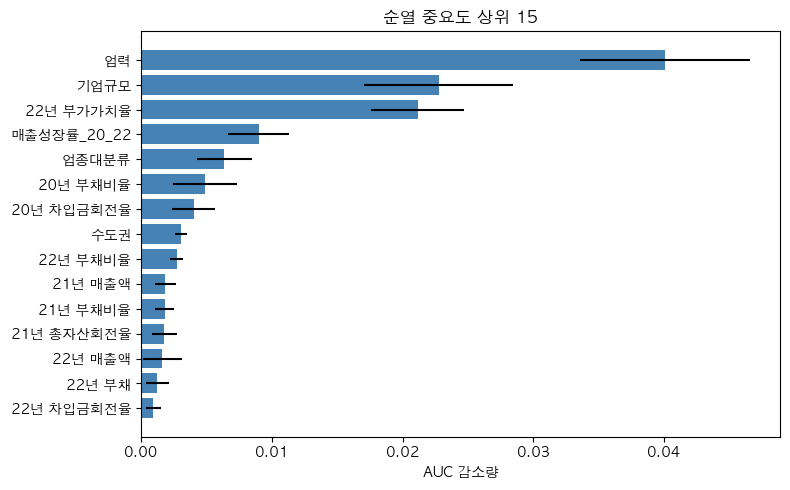

,feature,importance,std
3,업력,0.0401,0.0065
0,기업규모,0.0228,0.0057
31,22년 부가가치율,0.0212,0.0036
5,매출성장률_20_22,0.0090,0.0023
1,업종대분류,0.0064,0.0021
13,20년 부채비율,0.0049,0.0024
12,20년 차입금회전율,0.0040,0.0017
4,수도권,0.0031,0.0005
29,22년 부채비율,0.0027,0.0005
18,21년 매출액,0.0019,0.0008


In [12]:
# 순열 중요도 (부스팅, 평가 데이터 기준)
imp = permutation_importance(boost, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({"feature": X_test.columns, "importance": imp.importances_mean, "std": imp.importances_std})
importance = importance.sort_values("importance", ascending=False)
importance.to_csv("../outputs/importance.csv", index=False, encoding="utf-8-sig")

top = importance.head(15)
plt.figure(figsize=(8, 5))
plt.barh(top["feature"][::-1], top["importance"][::-1], xerr=top["std"][::-1], color="steelblue")
plt.xlabel("AUC 감소량")
plt.title("순열 중요도 상위 15")
plt.tight_layout()
plt.savefig("../outputs/model_importance.png")
plt.show()
importance.head(15).round(4)

In [13]:
# 로지스틱 계수. 방향을 보기 위함
pre = logit.named_steps["pre"]
names = list(num_cols) + list(pre.named_transformers_["cat"].get_feature_names_out(cat_cols))
coef = pd.DataFrame({"feature": names, "coef": logit.named_steps["model"].coef_[0]})
coef["abs"] = coef["coef"].abs()
coef.sort_values("abs", ascending=False).head(15).round(3)[["feature", "coef"]]

,feature,coef
30,기업규모_소기업,-0.555
43,업종대분류_S,0.485
31,기업규모_중견기업,0.480
23,22년 매출액,0.413
4,20년 총자산,-0.368
35,업종대분류_E,-0.335
33,기업규모_한시성중소기업,0.333
48,상장등록법인_코스닥상장기업,0.295
41,업종대분류_M,-0.278
13,21년 부채,-0.277


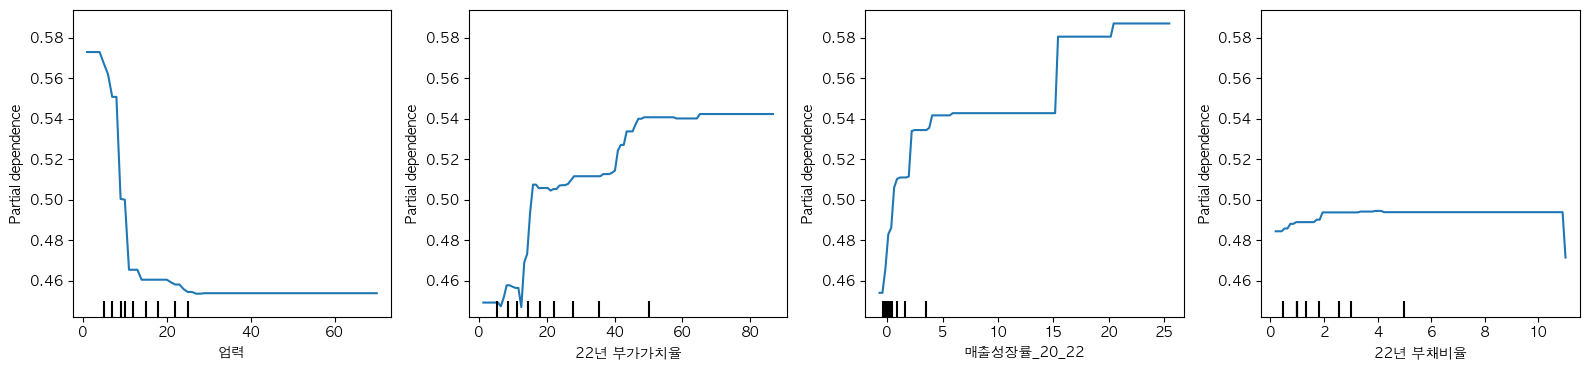

In [14]:
# 중요 변수의 부분 의존도 (부스팅)
features = ["업력", "22년 부가가치율", "매출성장률_20_22", "22년 부채비율"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(boost, X_test, features, ax=ax, percentiles=(0.02, 0.98))
plt.tight_layout()
plt.savefig("../outputs/model_pdp.png")
plt.show()

In [15]:
# 평가 데이터 예측 확률 저장. strategy 노트북에서 씀
pred_df = df.loc[X_test.index, ["기업규모", "업종대분류", "업력", "시도", "성장여부"]].copy()
pred_df["prob_boost"] = prob_boost
pred_df["prob_logit"] = prob_logit
pred_df.to_csv("../outputs/pred_test.csv", encoding="utf-8-sig")
pred_df.head()

,기업규모,업종대분류,업력,시도,성장여부,prob_boost,prob_logit
1293,중기업,C,17,부산,0,0.449711,0.535001
7363,소기업,F,9,서울,0,0.542558,0.539174
5096,중기업,E,10,경기,1,0.567737,0.498437
5142,소기업,C,17,경기,0,0.346867,0.392736
3443,소기업,C,15,경기,1,0.501245,0.475118
